In [5]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no job and no credits. The first run installs it (a few seconds), pinned to the version tested here.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    %pip install -q qiskit-aer==0.18.2

import time
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from scipy.optimize import milp, LinearConstraint, Bounds, minimize

# check.py sits next to this notebook: it loads the grids and checks placements
from check import load_grid, seen_buses, check_placement, brute_force_best, bits_to_buses

sim = AerSimulator()

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


IEEE 14-bus | 14 buses, 20 lines
IEEE 14-bus, 6-substation piece | buses [2, 3, 5, 6, 10, 11]


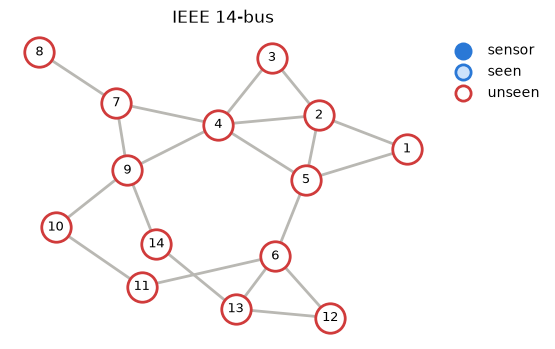

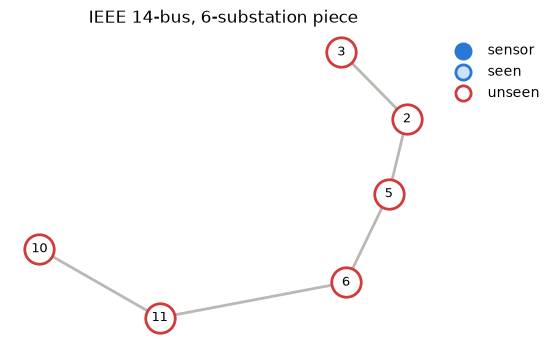

In [11]:
##LOADING AND DRAWING THE GRID: from starter.ipynb
grid300 = load_grid("ieee300.json")
grid14 = load_grid("ieee14.json")
piece = load_grid("ieee14_piece6.json")
print(grid14["name"], "|", len(grid14["buses"]), "buses,", len(grid14["lines"]), "lines")
print(piece["name"], "| buses", piece["buses"])


def layout(g):
    # networkx is only used to lay out the drawing; without it, buses go on a circle
    try:
        import networkx as nx
        return nx.kamada_kawai_layout(nx.Graph(g["lines"]))
    except ImportError:
        angle = np.linspace(0, 2 * np.pi, len(g["buses"]), endpoint=False)
        return {b: (np.cos(a), np.sin(a)) for b, a in zip(g["buses"], angle)}


def draw_grid(g, chosen=(), title="", pos=None):
    pos = pos or layout(g)
    seen = seen_buses(g, chosen)
    fig, ax = plt.subplots(figsize=(5.5, 4))
    for a, b in g["lines"]:
        ax.plot(*zip(pos[a], pos[b]), color="#b9b8b3", lw=2, zorder=1)
    for b in g["buses"]:
        face = "#2a78d6" if b in chosen else ("#cde2fb" if b in seen else "white")
        ring = "#2a78d6" if b in seen else "#d03b3b"
        ax.scatter(*pos[b], s=450, c=face, edgecolors=ring, linewidths=2, zorder=2)
        ax.annotate(str(b), pos[b], ha="center", va="center", fontsize=9, zorder=3,
                    color="white" if b in chosen else "black")
    for label, face, ring in [("sensor", "#2a78d6", "#2a78d6"), ("seen", "#cde2fb", "#2a78d6"), ("unseen", "white", "#d03b3b")]:
        ax.scatter([], [], s=120, c=face, edgecolors=ring, linewidths=2, label=label)
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    ax.set_title(title or g["name"])
    ax.margins(0.08)
    ax.axis("off")
    plt.show()


pos14 = layout(grid14)              # one layout, so the piece sits where it is in the full grid
draw_grid(grid14, pos=pos14)
draw_grid(piece, pos=pos14)

In [12]:
#STEP 2 of QAOA_IQAE_verification_guide.pdf

'''
Each bit is one bus: 1 means a sensor is placed there. Before any quantum check, confirm the
answer is a legal placement and compare its size to the exact ILP optimum. This needs no
quantum hardware and catches most mistakes.

• Valid means every bus is seen enough times (N-1 redundancy: twice) after accounting for
zero-injection buses.
• Optimal means valid and the same sensor count as the ILP minimum.
• The verifier script prints this as section [1] for the best bit strings in the QAOA distribution.
'''

#ILP placement (from starter.ipynb)

def ilp_placement(g, twice=False):
    # Exact minimum: one 0/1 variable per bus, and for every bus
    # (sensors on it or its neighbors) >= 1, or >= 2 with twice=True (N-1 stretch)
    buses = g["buses"]
    A = np.array([[1 if c == b or c in g["neighbors"][b] else 0 for c in buses] for b in buses])
    res = milp(c=np.ones(len(buses)), constraints=LinearConstraint(A, lb=2 if twice else 1),
               integrality=np.ones(len(buses)), bounds=Bounds(0, 1))
    return [b for b, x in zip(buses, res.x) if x > 0.5]



In [15]:
ilp_placement(grid14)
#ilp_placement(grid300)

[2, 7, 11, 13]

In [ ]:
#how to reduce 14 to 4??

ilp_14_string = "01000010001010"